**IMPORT**

---





In [ ]:
# Standard Libraries & Environment
import os
import math
from collections import Counter
from google.colab import drive

# Data Manipulation & Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Machine Learning Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from imblearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

# Imbalanced Data Handling
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTENC
from imblearn.over_sampling import BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation Metrics
from sklearn.metrics import classification_report, f1_score, roc_auc_score, confusion_matrix

**CONFIG**

---



In [ ]:
SEED = 1

In [ ]:
os.chdir('/content')
!curl -L -o train.csv "https://drive.google.com/uc?export=download&id=1FnAiRcCKfOLqbI9r4SmS641JuBslLGYz"
!curl -L -o test.csv "https://drive.google.com/uc?export=download&id=16H6iBH9vRC2w_gIW61RFRApshPQgnW7y"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 2407k  100 2407k    0     0  1265k      0  0:00:01  0:00:01 --:--:-- 4621k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  375k  100  375k    0     0   279k      0  0:00:01  0:00:01 --:--:--  122M


In [ ]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

**EXPLORATORY DATA ANALYSIS**

---

1. Seberapa tidak seimbang (imbalanced) distribusi target electricity_shutdown dan berapa persentase kelas positifnya?


In [ ]:
print("====== Distribusi Target ======")
print(train_df['electricity_shutdown'].value_counts())

====== Distribusi Target ======
electricity_shutdown
0.0    11100
1.0       89
Name: count, dtype: int64


In [ ]:
print("====== Persentase Target ======")
print(train_df['electricity_shutdown'].value_counts(normalize=True) * 100)

====== Persentase Target ======
electricity_shutdown
0.0    99.204576
1.0     0.795424
Name: proportion, dtype: float64


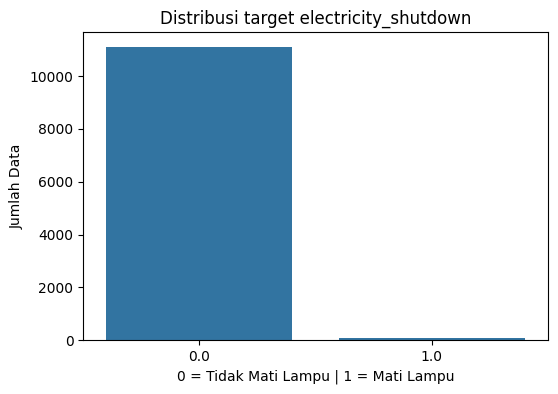

In [ ]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=train_df, x='electricity_shutdown')
plt.title('Distribusi target electricity_shutdown')
plt.xlabel('0 = Tidak Mati Lampu | 1 = Mati Lampu')
plt.ylabel('Jumlah Data')

plt.show()

Distribusi target electricity_shutdown pada dataset train.csv sangatlah tidak seimbang dengan persentase kelas positif berada pada 0.795424%

2. Bagaimana karakter distribusi precipitation dan apakah terdapat zero-inflation?

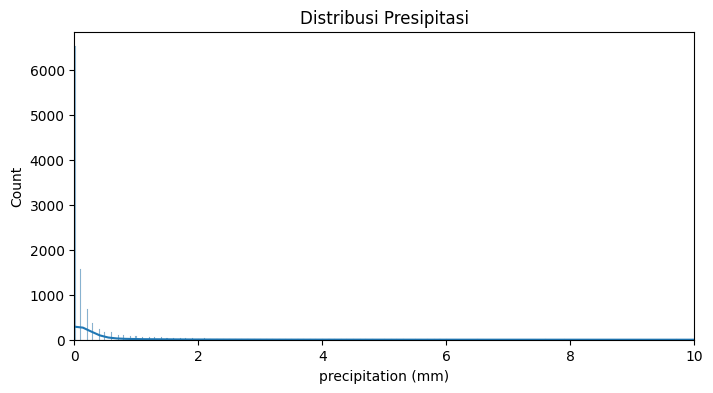

Skewness: 6.433435917895772
Kurtosis: 56.694706704981954
Jumlah nilai nol : 6,528
Total data       : 14,016
Proporsi nol aktual  : 46.58%
P(X=0) Poisson teori : 66.06%
Selisih (excess zero): -19.49%

=================== Kesimpulan ===================
Distribusi precipitation bersifat heavily right-skewed 
(skewness=6.43, kurtosis=56.69), 
menunjukkan mayoritas hari memiliki curah hujan rendah atau nol.
Tidak terdeteksi zero-inflation signifikan. 
Selisih proporsi nol aktual vs Poisson hanya -19.49%.


In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(train_df['precipitation (mm)'], kde=True)
plt.title('Distribusi Presipitasi')
plt.xlim(0, 10)
plt.show()

zero_count = (train_df['precipitation (mm)'] == 0).sum()
total = len(train_df)
zero_pct = zero_count / total * 100

mean_presipitasi = train_df['precipitation (mm)'].mean()
distribusi_poisson = math.e ** -(mean_presipitasi)
selisih = zero_pct - (distribusi_poisson * 100)


print(f"Skewness: {train_df['precipitation (mm)'].skew()}")
print(f"Kurtosis: {train_df['precipitation (mm)'].kurt()}")

print(f"Jumlah nilai nol : {zero_count:,}")
print(f"Total data       : {total:,}")
print(f"Proporsi nol aktual  : {zero_pct:.2f}%")
print(f"P(X=0) Poisson teori : {distribusi_poisson*100:.2f}%")
print(f"Selisih (excess zero): {selisih:.2f}%")

print("\n=================== Kesimpulan ===================")
print(f"Distribusi precipitation bersifat heavily right-skewed "
      f"\n(skewness={train_df['precipitation (mm)'].skew():.2f}, "
      f"kurtosis={train_df['precipitation (mm)'].kurt():.2f}), "
      f"\nmenunjukkan mayoritas hari memiliki curah hujan rendah atau nol.")

if selisih > 10:
    print(f"Terdapat zero-inflation: proporsi nol aktual ({zero_pct:.2f}%) "
          f"jauh melebihi ekspektasi Poisson ({distribusi_poisson*100:.2f}%), "
          f"dengan excess zero sebesar {selisih:.2f}%. "
          f"Data memerlukan penanganan zero-inflation (misal ZIP model atau "
          f"pemisahan klasifikasi hujan/tidak hujan).")
else:
    print(f"Tidak terdeteksi zero-inflation signifikan. "
          f"\nSelisih proporsi nol aktual vs Poisson hanya {selisih:.2f}%.")

3. Fitur cuaca apa yang memiliki korelasi tertinggi dengan precipitation?

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129 (\x81) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


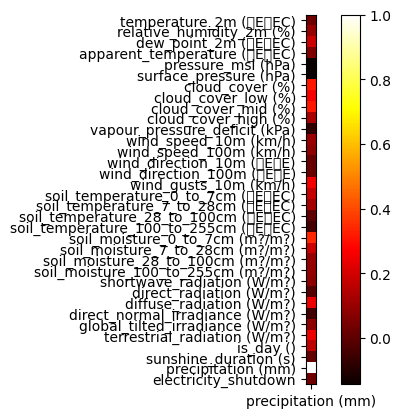

In [ ]:
cols = train_df.columns
numeric_cols = [col for col in cols if ((train_df[col].dtype == int or train_df[col].dtype == float) and col != "ID")]
train_df_numeric_cols = train_df[numeric_cols]

corr = train_df_numeric_cols.corr()
precipitation_corr = corr[["precipitation (mm)"]]
precipitation_corr

plt.imshow(precipitation_corr)
plt.colorbar()
plt.hot()
plt.xticks([0], ["precipitation (mm)"])
plt.yticks(range(len(numeric_cols)), numeric_cols)
plt.show()

4. Apakah terdapat pola temporal (jam/bulan/hari) pada shutdown listrik dan kapan puncaknya terjadi?

In [ ]:
df_here = train_df.copy()

# Convert ke datetime
df_here['time'] = pd.to_datetime(df_here['time'])

# ekstak fitur waktu
df_here['hour'] = df_here['time'].dt.hour
df_here['day'] = df_here['time'].dt.day
df_here['month'] = df_here['time'].dt.month
df_here['dayofweek'] = df_here['time'].dt.dayofweek  # Hari 0 = Senin

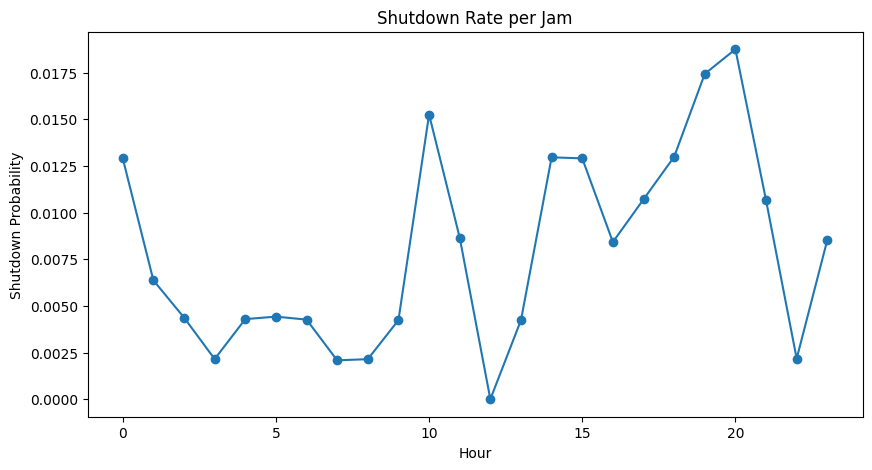

Peak hour: 20


In [ ]:
hourly = df_here.groupby('hour')['electricity_shutdown'].mean()

plt.figure(figsize=(10,5))
hourly.plot(marker='o')
plt.title("Shutdown Rate per Jam")
plt.xlabel("Hour")
plt.ylabel("Shutdown Probability")
plt.show()

print("Peak hour:", hourly.idxmax())

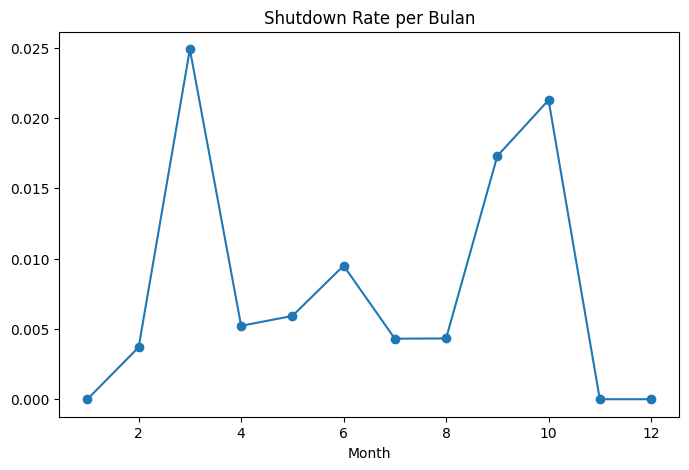

Peak month: 3


In [ ]:
monthly = df_here.groupby('month')['electricity_shutdown'].mean()

plt.figure(figsize=(8,5))
monthly.plot(marker='o')
plt.title("Shutdown Rate per Bulan")
plt.xlabel("Month")
plt.show()

print("Peak month:", monthly.idxmax())

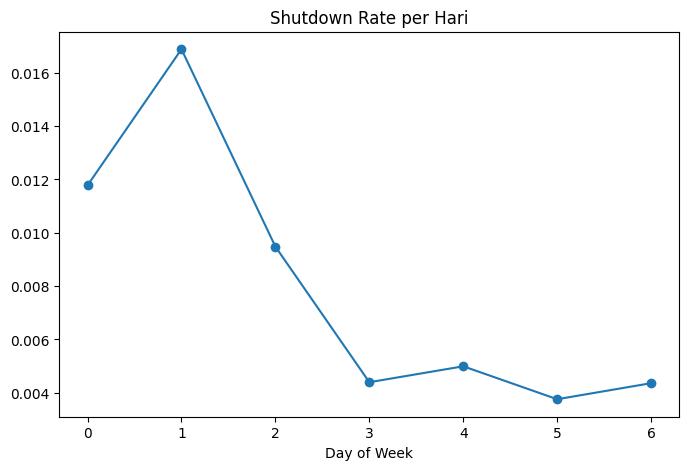

Peak day: hari ke 1


In [ ]:
daily = df_here.groupby('dayofweek')['electricity_shutdown'].mean()

plt.figure(figsize=(8,5))
daily.plot(marker='o')
plt.title("Shutdown Rate per Hari")
plt.xlabel("Day of Week")
plt.show()

print("Peak day: hari ke", daily.idxmax())

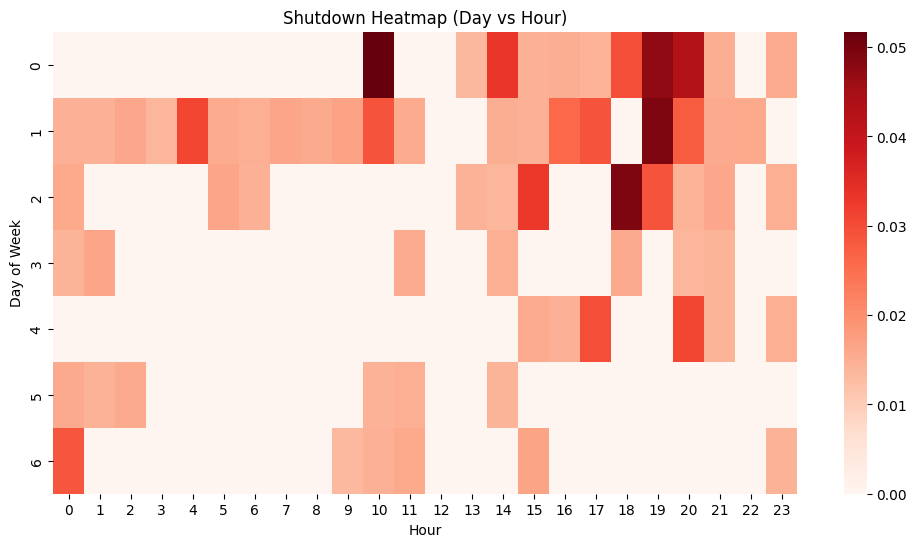

In [ ]:
pivot = df_here.pivot_table(
    values='electricity_shutdown',
    index='dayofweek',
    columns='hour',
    aggfunc='mean'
)

plt.figure(figsize=(12,6))
sns.heatmap(pivot, cmap='Reds')
plt.title("Shutdown Heatmap (Day vs Hour)")
plt.xlabel("Hour")
plt.ylabel("Day of Week")
plt.show()

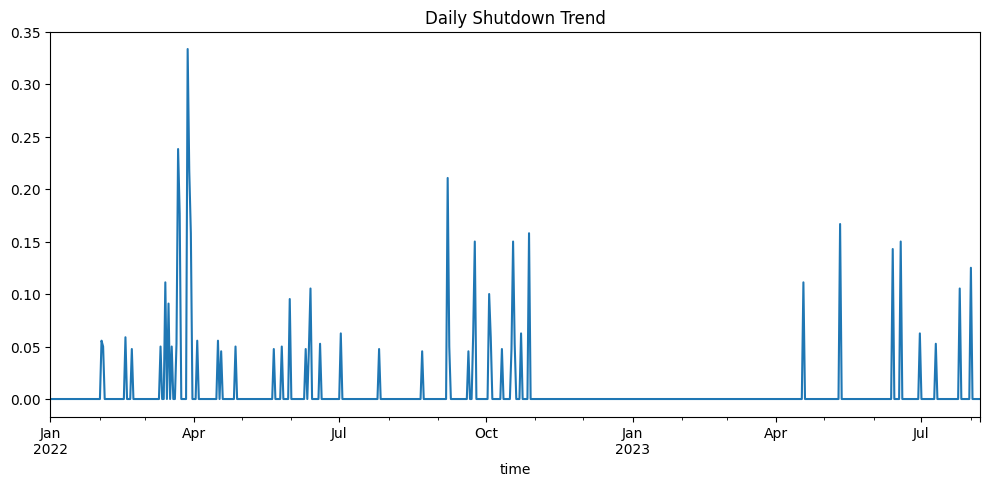

In [ ]:
ts = df_here.set_index('time')['electricity_shutdown'].resample('D').mean()

plt.figure(figsize=(12,5))
ts.plot()
plt.title("Daily Shutdown Trend")
plt.show()

Berdasarkan analisis pola temporal:

*   **Pola Jam (Hourly):** Tingkat *shutdown* listrik mencapai puncaknya pada **pukul 20:00 (jam 8 malam)**. Ini menunjukkan bahwa kemungkinan mati lampu paling tinggi terjadi pada jam tersebut.
*   **Pola Bulan (Monthly):** Tingkat *shutdown* listrik tertinggi terjadi pada **bulan Maret**. Ini bisa mengindikasikan adanya faktor musiman seperti perubahan cuaca ekstrem atau peningkatan aktivitas tertentu di bulan tersebut.
*   **Pola Hari dalam Seminggu (Daily):** Tingkat *shutdown* listrik paling tinggi terjadi pada **hari ke-1 (Selasa)** (dengan hari 0 = Senin). Hal ini mungkin terkait dengan pola penggunaan listrik atau aktivitas perbaikan/pemeliharaan.

Halaman panas (heatmap) secara visual mengkonfirmasi dan memperjelas pola ini, menunjukkan kombinasi waktu (hari dalam seminggu dan jam) di mana probabilitas *shutdown* listrik paling tinggi. Misalnya, pada hari Selasa (Day 1), ada peningkatan probabilitas *shutdown* di sore hari dan puncaknya sekitar pukul 20:00.

**MODELLING**

---

**Handle Missing Value**

In [ ]:
print(f"Total baris awal: {train_df.shape[0]}")

cleaned_df = train_df.copy()

cleaned_df = cleaned_df.dropna(subset=['electricity_shutdown'])

col_map = {c: c.encode('ascii', 'ignore').decode().strip() for c in cleaned_df.columns}
cleaned_df.rename(columns=col_map, inplace=True)

# Sort Time
train_df['time'] = pd.to_datetime(train_df['time'])
cleaned_df = cleaned_df.sort_values('time').reset_index(drop=True)

# Time-Series Imputation Untuk Fitur Cuaca
kolom_numerik = cleaned_df.select_dtypes(include=['float64', 'int64']).columns
cleaned_df[kolom_numerik] = cleaned_df[kolom_numerik].interpolate(method='linear', limit_direction='both')
cleaned_df[kolom_numerik] = cleaned_df[kolom_numerik].ffill().bfill()

print(cleaned_df.isnull().sum()[cleaned_df.isnull().sum() > 0])

Total baris awal: 14016
Series([], dtype: int64)


**Feature Engineering**

In [ ]:
processed_df = cleaned_df.copy()

#Temporal Features
processed_df['hour'] = train_df['time'].dt.hour
processed_df['dayofweek'] = train_df['time'].dt.dayofweek
processed_df['month'] = train_df['time'].dt.month

processed_df = processed_df.drop(columns=['time'], errors='ignore')

#Cyclical encoding
processed_df['hour_sin'] = np.sin(2*np.pi*processed_df['hour']/24)
processed_df['hour_cos'] = np.cos(2*np.pi*processed_df['hour']/24)
processed_df['month_sin'] = np.sin(2*np.pi*processed_df['month']/12)
processed_df['month_cos'] = np.cos(2*np.pi*processed_df['month']/12)

#Precipitation Features
# processed_df['precip_log'] = np.log1p(train_df['precipitation (mm)'])
# processed_df['is_rain'] = (train_df['precipitation (mm)'] > 0).astype(int)
# processed_df['heavy_rain'] = (train_df['precipitation (mm)'] > train_df['precipitation (mm)'].quantile(0.95)).astype(int)

#Rolling & Lag Features
# for lag in [1, 3, 6, 12, 24]:
#     processed_df[f'precip_lag_{lag}'] = train_df['precipitation (mm)'].shift(lag)

# # processed_df['precip_rolling_6h'] = train_df['precipitation (mm)'].rolling(6).mean()
# processed_df['wind_rolling_6h'] = train_df['wind_speed_10m (km/h)'].rolling(6, min_periods=1).mean()
# processed_df['pressure_drop_3h'] = train_df['surface_pressure (hPa)'].diff(3).fillna(0)

# #Interaction Features
# # train_df['storm_risk'] = train_df['wind_speed_10m (km/h)'] * train_df['precipitation (mm)']
# processed_df['humid_heat'] = train_df['temperature_2m (EEC)'] * train_df['relative_humidity_2m (%)']
# processed_df['cloud_humidity_index'] = train_df['cloud_cover (%)'] * train_df['relative_humidity_2m (%)']

# #Wind Features
# processed_df['wind_gust_ratio'] = train_df['wind_gusts_10m (km/h)'] / (train_df['wind_speed_10m (km/h)'] + 1e-5)

# #Pressure & Instability Indicators
# processed_df['pressure_diff'] = train_df['pressure_msl (hPa)'] - train_df['surface_pressure (hPa)']

In [ ]:
# Drop Precipitation (Diperuntukkan untuk TP2)
processed_df = processed_df.drop(columns=['time', 'precipitation (mm)', "ID"], errors='ignore')

**Split Feature & Target**

In [ ]:
default_cols = list(set(cleaned_df.columns.tolist()) - {'time', 'precipitation (mm)', "ID"})
used_cols = default_cols.copy()

# print(cleaned_df.columns)
# print(default_cols)

# processed_df = processed_df[used_cols] # GA JADI PAKE FE (KALO JADI, HAPUS LINE INI)
X = processed_df.drop(columns=['electricity_shutdown'])
y = processed_df['electricity_shutdown']

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print(f"Jumlah baris X_train: {X_train.shape[0]}")
print(f"Jumlah baris X_val: {X_val.shape[0]}\n")

Jumlah baris X_train: 8951
Jumlah baris X_val: 2238



**Handle Imbalance**

In [ ]:
print("Distribusi y_train sebelum sampling:", Counter(y_train))

# Imputer untuk NaN hasil engineering
imputer = KNNImputer()

X_train_clean = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_clean = pd.DataFrame(imputer.transform(X_val), columns=X_val.columns, index=X_val.index)

# SMOTENC
categorical_cols = ["is_day ()"]
categorical_idxs = [list(X_train.columns).index(col) for col in categorical_cols]
resample_method = SMOTENC(categorical_features=categorical_idxs, random_state=42)
X_train_resampled, y_train_resampled = resample_method.fit_resample(X_train_clean, y_train)

print("Distribusi y_train setelah SMOTENC:", Counter(y_train_resampled))

Distribusi y_train sebelum sampling: Counter({0.0: 8880, 1.0: 71})
Distribusi y_train setelah SMOTENC: Counter({0.0: 8880, 1.0: 8880})


**Decision Tree**

=== COST-SENSITIVE LOGISTIC REGRESSION EVALUATION RESULT ===
F1-Score (Binary) : 0.2222
F1-Score (Macro)  : 0.6072
ROC-AUC Score     : 0.6339

Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      2220
         1.0       0.19      0.28      0.22        18

    accuracy                           0.98      2238
   macro avg       0.59      0.63      0.61      2238
weighted avg       0.99      0.98      0.99      2238



,0
surface_pressure (hPa),0.088466
soil_moisture_100_to_255cm (m?/m?),0.087398
wind_direction_10m (EE),0.082457
soil_temperature_7_to_28cm (EEC),0.078091
dew_point_2m (EEC),0.065140
hour,0.049124
cloud_cover (%),0.044865
cloud_cover_mid (%),0.043508
direct_normal_irradiance (W/m?),0.041231
wind_speed_10m (km/h),0.041001


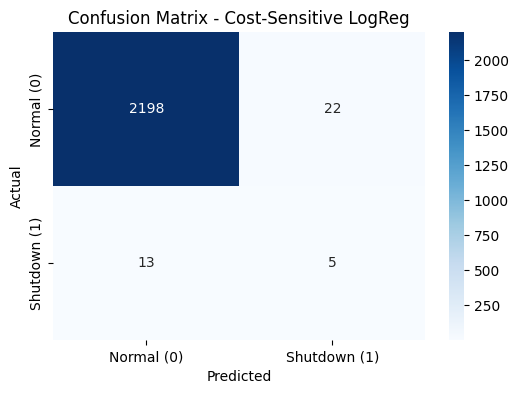

In [ ]:
model = DecisionTreeClassifier(random_state=SEED)

tree_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", model)
])

tree_pipeline.fit(X_train_clean, y_train)

y_pred = tree_pipeline.predict(X_val_clean)
y_pred_proba = tree_pipeline.predict_proba(X_val_clean)[:, 1]

print("=== COST-SENSITIVE LOGISTIC REGRESSION EVALUATION RESULT ===")
print(f"F1-Score (Binary) : {f1_score(y_val, y_pred, average='binary'):.4f}")
print(f"F1-Score (Macro)  : {f1_score(y_val, y_pred, average='macro'):.4f}")
print(f"ROC-AUC Score     : {roc_auc_score(y_val, y_pred_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, y_pred))

cm = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal (0)', 'Shutdown (1)'], yticklabels=['Normal (0)', 'Shutdown (1)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Cost-Sensitive LogReg')

feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(feature_importance)

**Random Forest**

F1 per fold (Random Forest with SFS): [0.74285714 0.88235294 0.77777778 0.77777778]
Mean F1 (Random Forest with SFS): 0.7951914098972922

=== RANDOM FOREST (SFS) EVALUATION RESULT ===
F1-Score (Binary) : 0.0331
F1-Score (Macro)  : 0.3941
ROC-AUC Score     : 0.8145

Classification Report:
              precision    recall  f1-score   support

  Normal (0)       1.00      0.61      0.75      2220
Shutdown (1)       0.02      0.83      0.03        18

    accuracy                           0.61      2238
   macro avg       0.51      0.72      0.39      2238
weighted avg       0.99      0.61      0.75      2238



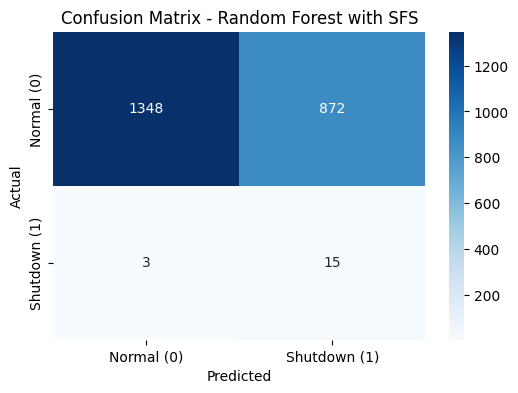

,ID,electricity_shutdown
0,14017,0
1,14018,0
2,14019,0
3,14020,0
4,14021,0
...,...,...
95,14163,0
96,14164,0
97,14167,0
98,14168,0


Submission file 'submission_rf_sfs.csv' created successfully using Random Forest with SFS.


In [ ]:
# KNNImputer
imputer_rf = KNNImputer()
X_train_clean_rf = pd.DataFrame(imputer_rf.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_clean_rf = pd.DataFrame(imputer_rf.transform(X_val), columns=X_val.columns, index=X_val.index)

# RandomUnderSampler
resample_method_rf = RandomUnderSampler(random_state=SEED)
X_train_resampled_rf, y_train_resampled_rf = resample_method_rf.fit_resample(X_train_clean_rf, y_train)

model_rf = RandomForestClassifier(random_state=SEED)

cv_rf = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED
)

scores_rf = cross_val_score(
    Pipeline([("scaler", StandardScaler()), ("model", model_rf)]),
    X_train_resampled_rf,
    y_train_resampled_rf,
    scoring="f1",
    cv=cv_rf,
    n_jobs=-1,
)

sfs_rf = SFS(estimator=model_rf, k_features='best', scoring='f1', cv=cv_rf, n_jobs=-1, verbose=0)

X_train_selected_rf = sfs_rf.fit_transform(X_train_resampled_rf.values, y_train_resampled_rf.values)
X_val_selected_rf = sfs_rf.transform(X_val_clean_rf.values)

rf_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('model', model_rf)
])

rf_pipeline.fit(X_train_selected_rf, y_train_resampled_rf)

y_pred_rf = rf_pipeline.predict(X_val_selected_rf)
y_pred_proba_rf = rf_pipeline.predict_proba(X_val_selected_rf)[:, 1]

print("F1 per fold (Random Forest with SFS):", scores_rf)
print("Mean F1 (Random Forest with SFS):", scores_rf.mean())

print("\n=== RANDOM FOREST (SFS) EVALUATION RESULT ===")
print(f"F1-Score (Binary) : {f1_score(y_val, y_pred_rf, average='binary'):.4f}")
print(f"F1-Score (Macro)  : {f1_score(y_val, y_pred_rf, average='macro'):.4f}")
print(f"ROC-AUC Score     : {roc_auc_score(y_val, y_pred_proba_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf, target_names=['Normal (0)', 'Shutdown (1)']))

cm_rf = confusion_matrix(y_val, y_pred_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal (0)', 'Shutdown (1)'], yticklabels=['Normal (0)', 'Shutdown (1)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Random Forest with SFS')
plt.show()

# --- Submission ---
test_clean_rf = test_df.copy()

col_map_rf = {c: c.encode('ascii', 'ignore').decode().strip() for c in test_clean_rf.columns}
test_clean_rf.rename(columns=col_map_rf, inplace=True)

# Time sort
test_clean_rf['time'] = pd.to_datetime(test_clean_rf['time'])
test_clean_rf = test_clean_rf.sort_values('time').reset_index(drop=True)

# Time-Series Imputation
num_cols_rf = test_clean_rf.select_dtypes(include=['float64', 'int64']).columns
num_cols_rf = [c for c in num_cols_rf if c != 'ID']
test_clean_rf[num_cols_rf] = test_clean_rf[num_cols_rf].interpolate(method='linear', limit_direction='both')
test_clean_rf[num_cols_rf] = test_clean_rf[num_cols_rf].ffill().bfill()

# Temporal Features
test_clean_rf['hour'] = test_clean_rf['time'].dt.hour
test_clean_rf['dayofweek'] = test_clean_rf['time'].dt.dayofweek
test_clean_rf['month'] = test_clean_rf['time'].dt.month

# Cyclical Encoding
test_clean_rf['hour_sin'] = np.sin(2 * np.pi * test_clean_rf['hour'] / 24)
test_clean_rf['hour_cos'] = np.cos(2 * np.pi * test_clean_rf['hour'] / 24)
test_clean_rf['month_sin'] = np.sin(2 * np.pi * test_clean_rf['month'] / 12)
test_clean_rf['month_cos'] = np.cos(2 * np.pi * test_clean_rf['month'] / 12)

cols_to_drop_rf = ['time', 'precipitation (mm)', 'ID']
X_test_rf = test_clean_rf.drop(columns=[c for c in cols_to_drop_rf if c in test_clean_rf.columns])

X_test_rf = X_test_rf[X_train.columns]

X_test_imputed_rf = pd.DataFrame(imputer_rf.transform(X_test_rf), columns=X_test_rf.columns, index=X_test_rf.index)

X_test_selected_rf = sfs_rf.transform(X_test_imputed_rf.values)

y_pred_test_rf = rf_pipeline.predict(X_test_selected_rf)

submission_df_rf = pd.DataFrame({'ID': test_clean_rf['ID'], 'electricity_shutdown': y_pred_test_rf})

submission_df_rf['electricity_shutdown'] = submission_df_rf['electricity_shutdown'].astype(int)

display(submission_df_rf.head(100))

# Save to CSV
submission_df_rf.to_csv('submission_rf_sfs.csv', index=False)
print("Submission file 'submission_rf_sfs.csv' created successfully using Random Forest with SFS.")


**kNN**

=== K-NEAREST NEIGHBOR EVALUATION RESULT ===
F1-Score (Binary) : 0.0719
F1-Score (Macro)  : 0.5179
ROC-AUC Score     : 0.7802

Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.99      0.94      0.96      2220
Shutdown (1)       0.04      0.33      0.07        18

    accuracy                           0.93      2238
   macro avg       0.52      0.63      0.52      2238
weighted avg       0.99      0.93      0.96      2238



Text(0.5, 1.0, 'Confusion Matrix - Cost-Sensitive kNN')

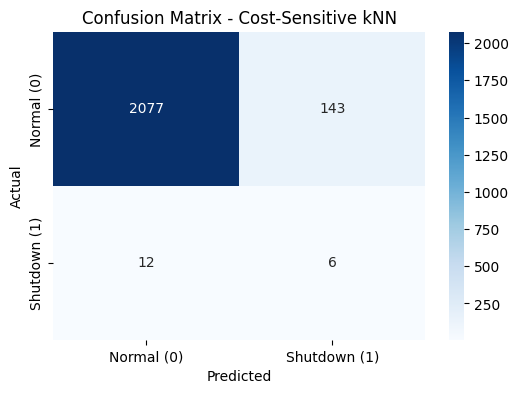

In [ ]:
knn_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(
        n_neighbors=7,
        weights='distance',
        metric='euclidean',
        n_jobs=-1
    ))
])

knn_pipeline.fit(X_train_resampled, y_train_resampled)


y_pred_knn   = knn_pipeline.predict(X_val_clean)
y_proba_knn  = knn_pipeline.predict_proba(X_val_clean)[:, 1]


print("=== K-NEAREST NEIGHBOR EVALUATION RESULT ===")
print(f"F1-Score (Binary) : {f1_score(y_val, y_pred_knn, average='binary'):.4f}")
print(f"F1-Score (Macro)  : {f1_score(y_val, y_pred_knn, average='macro'):.4f}")
print(f"ROC-AUC Score     : {roc_auc_score(y_val, y_proba_knn):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, y_pred_knn,
                            target_names=['Normal (0)', 'Shutdown (1)']))

cm = confusion_matrix(y_val, y_pred_knn)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal (0)', 'Shutdown (1)'], yticklabels=['Normal (0)', 'Shutdown (1)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Cost-Sensitive kNN')

**Logistic Regression**

=== COST-SENSITIVE LOGISTIC REGRESSION EVALUATION RESULT ===
F1-Score (Binary) : 0.0410
F1-Score (Macro)  : 0.4482
ROC-AUC Score     : 0.8004

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.75      0.86      2220
         1.0       0.02      0.67      0.04        18

    accuracy                           0.75      2238
   macro avg       0.51      0.71      0.45      2238
weighted avg       0.99      0.75      0.85      2238



Text(0.5, 1.0, 'Confusion Matrix - Cost-Sensitive LogReg')

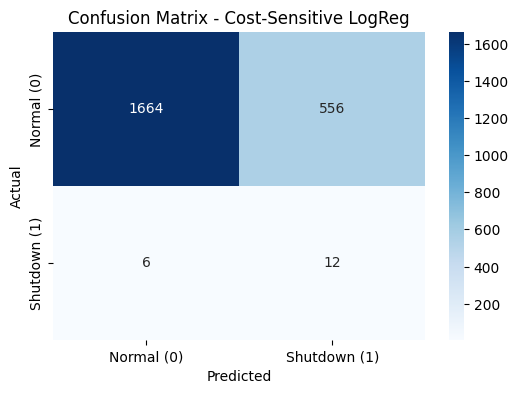

In [ ]:
logreg_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=SEED,
        n_jobs=-1
    ))
])
logreg_pipeline.fit(X_train_resampled, y_train_resampled)

y_pred_val = logreg_pipeline.predict(X_val_clean)
y_pred_proba = logreg_pipeline.predict_proba(X_val_clean)[:, 1]

print("=== COST-SENSITIVE LOGISTIC REGRESSION EVALUATION RESULT ===")
print(f"F1-Score (Binary) : {f1_score(y_val, y_pred_val, average='binary'):.4f}")
print(f"F1-Score (Macro)  : {f1_score(y_val, y_pred_val, average='macro'):.4f}")
print(f"ROC-AUC Score     : {roc_auc_score(y_val, y_pred_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, y_pred_val))

cm = confusion_matrix(y_val, y_pred_val)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal (0)', 'Shutdown (1)'], yticklabels=['Normal (0)', 'Shutdown (1)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Cost-Sensitive LogReg')

**Extreme Gradient Boost**

In [ ]:
print("Distribusi y_train sebelum sampling:", Counter(y_train))

# Imputer untuk NaN hasil engineering
imputer = KNNImputer()

X_train_xgb = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_xgb = pd.DataFrame(imputer.transform(X_val), columns=X_val.columns, index=X_val.index)

# RESAMPLING
counts = Counter(y_train)
target_min = int(counts[1] * 2)
target_maj = int(counts[0] / 10)

# Borderline-SMOTE (Oversample minority first)
smote = BorderlineSMOTE(sampling_strategy={1: target_min}, random_state=SEED, kind='borderline-1')
X_smote, y_smote = smote.fit_resample(X_train_xgb, y_train)

# Random Undersampler (Undersample majority second)
rus = RandomUnderSampler(sampling_strategy={0: target_maj}, random_state=SEED)
X_train_resampled_xgb, y_train_resampled_xgb = rus.fit_resample(X_smote, y_smote)

print("Distribusi y_train setelah Borderline-SMOTE:", Counter(y_train_resampled_xgb))

Distribusi y_train sebelum sampling: Counter({0.0: 8880, 1.0: 71})
Distribusi y_train setelah Borderline-SMOTE: Counter({0.0: 888, 1.0: 142})


=== BORDERLINE-SMOTE XGBOOST EVALUATION RESULT ===
F1-Score (Binary) : 0.4138
F1-Score (Macro)  : 0.7050
ROC-AUC Score     : 0.8041

Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      1.00      1.00      2220
         1.0       0.55      0.33      0.41        18

    accuracy                           0.99      2238
   macro avg       0.77      0.67      0.70      2238
weighted avg       0.99      0.99      0.99      2238



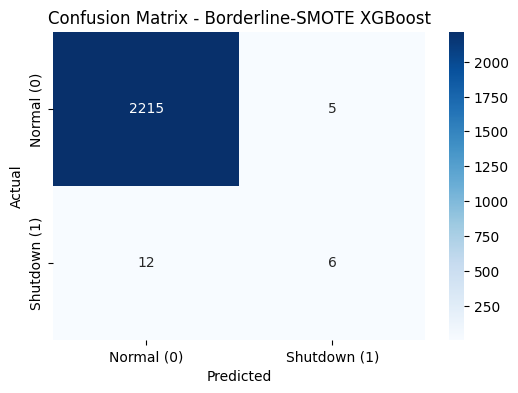

In [ ]:
xgb_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('model', XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=SEED,
        n_jobs=-1,
        eval_metric='logloss'
    ))
])

xgb_pipeline.fit(X_train_resampled_xgb, y_train_resampled_xgb)

y_pred_proba = xgb_pipeline.predict_proba(X_val_xgb)[:, 1]
y_pred_val = (y_pred_proba >= 0.74).astype(int)

print("=== BORDERLINE-SMOTE XGBOOST EVALUATION RESULT ===")
print(f"F1-Score (Binary) : {f1_score(y_val, y_pred_val, average='binary'):.4f}")
print(f"F1-Score (Macro)  : {f1_score(y_val, y_pred_val, average='macro'):.4f}")
print(f"ROC-AUC Score     : {roc_auc_score(y_val, y_pred_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, y_pred_val))

cm = confusion_matrix(y_val, y_pred_val)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal (0)', 'Shutdown (1)'], yticklabels=['Normal (0)', 'Shutdown (1)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Borderline-SMOTE XGBoost')
plt.show()

In [ ]:
test_clean = test_df.copy()

col_map = {c: c.encode('ascii', 'ignore').decode().strip() for c in test_clean.columns}
test_clean.rename(columns=col_map, inplace=True)

# Time sort
test_clean['time'] = pd.to_datetime(test_clean['time'])
test_clean = test_clean.sort_values('time').reset_index(drop=True)

# Time-Series Imputation
num_cols = test_clean.select_dtypes(include=['float64', 'int64']).columns
num_cols = [c for c in num_cols if c != 'ID'] # Exclude ID from interpolation
test_clean[num_cols] = test_clean[num_cols].interpolate(method='linear', limit_direction='both')
test_clean[num_cols] = test_clean[num_cols].ffill().bfill()

# Temporal Features
test_clean['hour'] = test_clean['time'].dt.hour
test_clean['dayofweek'] = test_clean['time'].dt.dayofweek
test_clean['month'] = test_clean['time'].dt.month

# Cyclical Encoding
test_clean['hour_sin'] = np.sin(2 * np.pi * test_clean['hour'] / 24)
test_clean['hour_cos'] = np.cos(2 * np.pi * test_clean['hour'] / 24)
test_clean['month_sin'] = np.sin(2 * np.pi * test_clean['month'] / 12)
test_clean['month_cos'] = np.cos(2 * np.pi * test_clean['month'] / 12)

cols_to_drop = ['time', 'precipitation (mm)', 'ID']
X_test = test_clean.drop(columns=[c for c in cols_to_drop if c in test_clean.columns])

X_test = X_test[X_train.columns]

# KNNImputer
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

y_pred_proba = xgb_pipeline.predict_proba(X_test_imputed)[:, 1]
y_pred_test = (y_pred_proba >= 0.74).astype(int)

submission = pd.DataFrame({
    'ID': test_clean['ID'],
    'electricity_shutdown': y_pred_test
})

submission.to_csv('submission.csv', index=False)
print('\nsubmission.csv saved ✓')
display(submission.head(10))


submission.csv saved ✓


,ID,electricity_shutdown
0,14017,0
1,14018,0
2,14019,0
3,14020,0
4,14021,0
5,14023,0
6,14024,0
7,14025,0
8,14026,0
9,14029,0


TEST PAKE RANDOM FOREST TAPI TAPI PAKE RANDOM UNDERSAMPLING

In [ ]:
processed_test_df = test_df.copy()

# Temporal Features
processed_test_df['hour'] = processed_test_df['time'].dt.hour
processed_test_df['dayofweek'] = processed_test_df['time'].dt.dayofweek
processed_test_df['month'] = processed_test_df['time'].dt.month

# Cyclical encoding
processed_test_df['hour_sin'] = np.sin(2*np.pi*processed_test_df['hour']/24)
processed_test_df['hour_cos'] = np.cos(2*np.pi*processed_test_df['hour']/24)
processed_test_df['month_sin'] = np.sin(2*np.pi*processed_test_df['month']/12)
processed_test_df['month_cos'] = np.cos(2*np.pi*processed_test_df['month']/12)

# Rolling & Lag Features
processed_test_df['wind_rolling_6h'] = processed_test_df['wind_speed_10m (km/h)'].rolling(6, min_periods=1).mean()
processed_test_df['pressure_drop_3h'] = processed_test_df['surface_pressure (hPa)'].diff(3).fillna(0)

# Interaction Features
processed_test_df['humid_heat'] = processed_test_df['temperature_2m (EEC)'] * processed_test_df['relative_humidity_2m (%)']
processed_test_df['cloud_humidity_index'] = processed_test_df['cloud_cover (%)'] * processed_test_df['relative_humidity_2m (%)']

# Wind Features
processed_test_df['wind_gust_ratio'] = processed_test_df['wind_gusts_10m (km/h)'] / (processed_test_df['wind_speed_10m (km/h)'] + 1e-5)

# Pressure & Instability Indicators
processed_test_df['pressure_diff'] = processed_test_df['pressure_msl (hPa)'] - processed_test_df['surface_pressure (hPa)']

processed_test_df = processed_test_df.drop(columns=['time', 'precipitation (mm)'], errors='ignore')

if 'ID' in processed_test_df.columns:
    processed_test_df = processed_test_df.drop(columns=['ID'])

aligned_test_df = processed_test_df[X_train_clean.columns]

print(f"Shape of aligned_test_df: {aligned_test_df.shape}")
print("Columns in aligned_test_df match X_train_clean.columns:")
print(list(aligned_test_df.columns) == list(X_train_clean.columns))# Make predictions using the Random Forest model
final_test_data = pd.DataFrame(imputer.transform(aligned_test_df), columns=aligned_test_df.columns, index=aligned_test_df.index)

y_pred_test_rf = rf_pipeline.predict(final_test_data)

submission_df_rf = pd.DataFrame({'ID': test_df['ID'], 'electricity_shutdown': y_pred_test_rf})

submission_df_rf['electricity_shutdown'] = submission_df_rf['electricity_shutdown'].astype(int)

display(submission_df_rf.head(100))

# Save to CSV
submission_df_rf.to_csv('submission_rf.csv', index=False)
print("Submission file 'submission_rf.csv' created successfully using Random Forest.")

AttributeError: Can only use .dt accessor with datetimelike values

In [ ]:
# submission_rf_df = pd.read_csv('submission_rf.csv')
# count_ones_rf = (submission_rf_df['electricity_shutdown'] == 1).sum()
# print(f"Jumlah '1' di kolom electricity_shutdown pada submission_rf.csv (Random Forest) adalah: {count_ones_rf}")

Test Pake XGBOOST

In [ ]:
test_df_processed = test_df.copy()

# Handle missing values
test_df_processed['time'] = pd.to_datetime(test_df_processed['time'])
test_df_processed = test_df_processed.sort_values('time').reset_index(drop=True)

# Time-Series Imputation Untuk Fitur Cuaca
kolom_numerik_test = test_df_processed.select_dtypes(include=['float64', 'int64']).columns
test_df_processed[kolom_numerik_test] = test_df_processed[kolom_numerik_test].interpolate(method='linear', limit_direction='both')
test_df_processed[kolom_numerik_test] = test_df_processed[kolom_numerik_test].ffill().bfill()

print("Missing values in test_df_processed after imputation:")
print(test_df_processed.isnull().sum()[test_df_processed.isnull().sum() > 0])


Missing values in test_df_processed after imputation:
Series([], dtype: int64)


In [ ]:
final_test_data = pd.DataFrame(imputer.transform(aligned_test_df), columns=aligned_test_df.columns, index=aligned_test_df.index)

y_pred_test_xgb = (xgb_pipeline.predict_proba(final_test_data)[:, 1] >= 0.74).astype(int)

submission_df_xgb = pd.DataFrame({'ID': test_df['ID'], 'electricity_shutdown': y_pred_test_xgb})

submission_df_xgb['electricity_shutdown'] = submission_df_xgb['electricity_shutdown'].astype(int)

display(submission_df_xgb.head(100))

# Save to CSV
submission_df_xgb.to_csv('submission.csv', index=False)
print("Submission file 'submission.csv' created successfully using XGBoost.")

NameError: name 'aligned_test_df' is not defined